In [1]:
import os
from dotenv import find_dotenv, load_dotenv

load_dotenv(find_dotenv())
src_path = os.environ.get('PROJECT_SRC')
os.chdir(src_path)

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import cop
import FES_scaling_factor
import geopandas as gpd
import FES_shapefile_LAs_matching
import LA_overlaps_within_gird_squares
import heat_tech_distribution
from tech_half_hourly_profile import scaling_half_hourly_profiles_grid_sqs, base_heat_pattern_per_technology
from Grid_squares_heat_tech_demand import calculate_heat_demand_for_grid_squares

In [3]:

weather_year = 2012
future_year = 2050
FES_year = '2022'
FES_scenario = 'LW'
grid_id = '-3.5_56.0'

<Axes: >

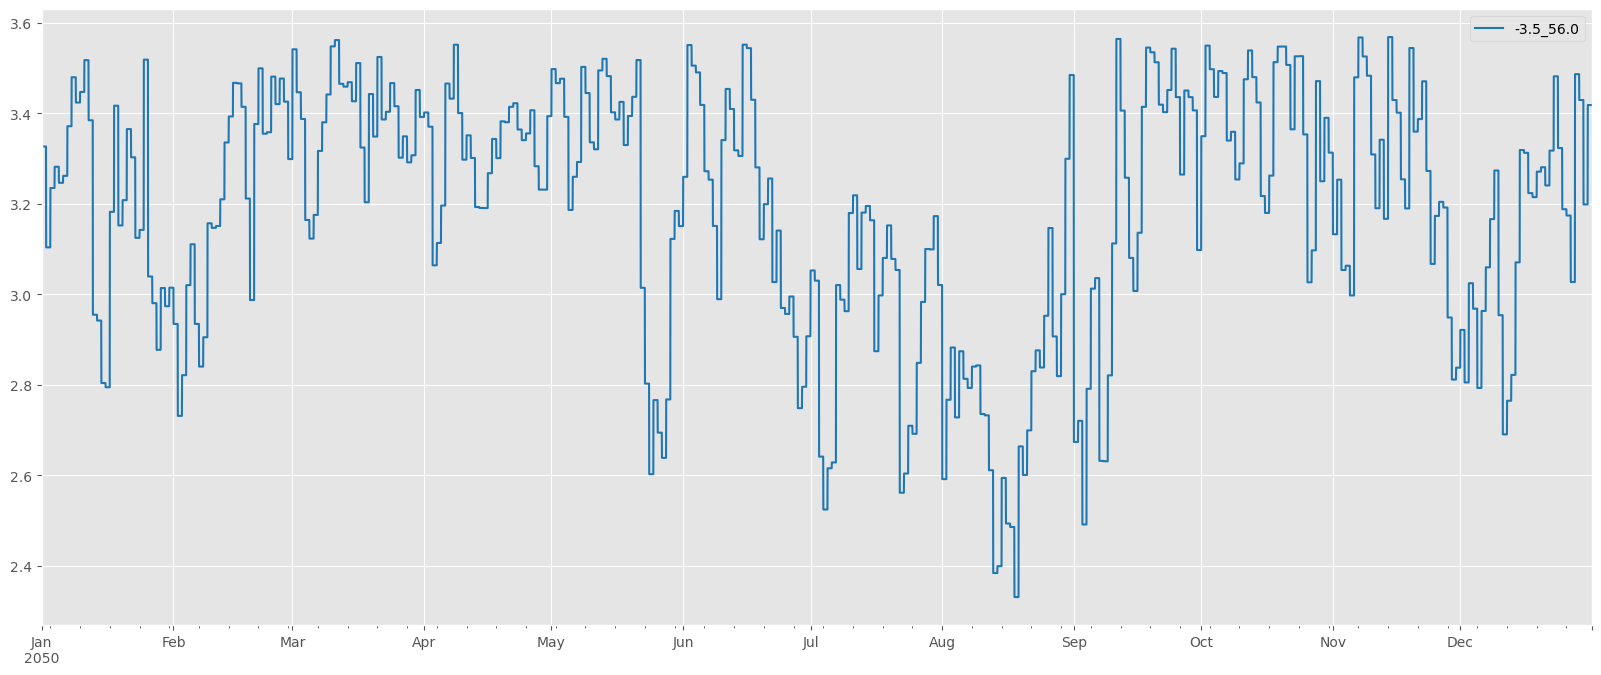

In [4]:
df_ASHP = cop.day_cop_for_year_grid_sq('ASHP', 'very good', future_year=future_year, weather_year=weather_year)
df_ASHP_grid_id = df_ASHP[[grid_id]]

plt.style.use('ggplot')
df_ASHP_grid_id.plot(figsize=(20,8), cmap='tab20')

<Axes: >

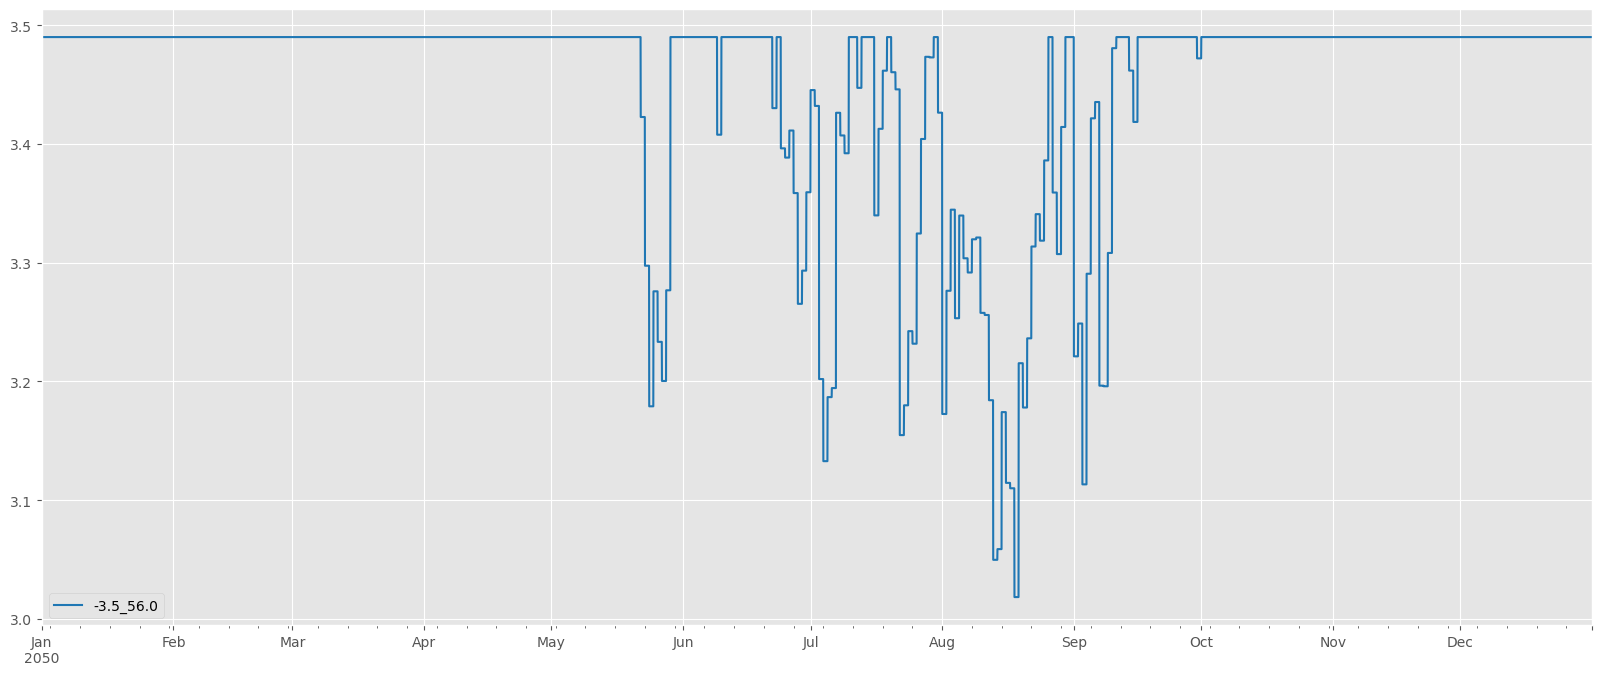

In [5]:
df_GSHP = cop.day_cop_for_year_grid_sq('GSHP', 'very good', future_year=future_year, weather_year=weather_year)
df_GSHP_grid_id = df_GSHP[[grid_id]]

plt.style.use('ggplot')
df_GSHP_grid_id.plot(figsize=(20,8), cmap='tab20')

In [6]:
LA_shapefile = gpd.read_file(r'data\LA_UK\new_version\UK_LAs_Boundaries_files\LAs_shapefile_2021\LAD_DEC_2021_GB_BFC.shp')
grid_squares =  gpd.read_file(r'data\LA_UK\new_version\data_call\UK_Atlite_Grid_sq.gpkg')

In [7]:
air_temp_df = pd.read_csv(f'data/LA_UK/new_version/air_temp_new/air_temp_{weather_year}.csv', index_col=0)
grid_sqs = [str(gid).strip() for gid in air_temp_df.columns]

In [8]:
LA_overlaps = LA_overlaps_within_gird_squares.calc_LA_overlap_within_grid_square(grid_squares,
                                                                                LA_shapefile,
                                                                                weather_year)
LA_overlaps  

,grid_x,grid_y,LA_Code,Local_Authority,long,lat,overlap_area,LA_area,overlap_percentage
Grid_ID,,,,,,,,,
-6.5_50.0,-6.50,50.00,E06000053,Isles of Scilly,-6.30217,49.9233,7.878469e+04,1.625142e+07,0.484787
-6.25_50.0,-6.25,50.00,E06000053,Isles of Scilly,-6.30217,49.9233,1.617263e+07,1.625142e+07,99.515213
-5.75_50.0,-5.75,50.00,E06000052,Cornwall,-4.64254,50.4502,5.036570e+07,3.548939e+09,1.419176
-5.5_50.0,-5.50,50.00,E06000052,Cornwall,-4.64254,50.4502,6.136620e+07,3.548939e+09,1.729142
-5.25_50.0,-5.25,50.00,E06000052,Cornwall,-4.64254,50.4502,1.940778e+08,3.548939e+09,5.468616
...,...,...,...,...,...,...,...,...,...
-1.0_60.5,-1.00,60.50,S12000027,Shetland Islands,-1.37344,60.5050,1.122228e+08,1.468514e+09,7.641929
-0.75_60.5,-0.75,60.50,S12000027,Shetland Islands,-1.37344,60.5050,2.375825e+07,1.468514e+09,1.617842
-1.25_60.75,-1.25,60.75,S12000027,Shetland Islands,-1.37344,60.5050,1.130301e+07,1.468514e+09,0.769690


In [9]:
df_merged = heat_tech_distribution.merge_shapefile_FES_heating_tech_file(grid_squares, 
                                                                             LA_overlaps, 
                                                                             future_year,
                                                                             FES_year, 
                                                                             FES_scenario,
                                                                             weather_year)
df_merged 
 

Sample FES LAs: ['Aberdeen City', 'Aberdeenshire', 'Adur', 'Allerdale', 'Amber Valley', 'Angus', 'Argyll And Bute', 'Arun', 'Ashfield', 'Ashford']
Sample Grid LAs: ['Isles Of Scilly' 'Cornwall' 'Plymouth' 'South Hams' 'Torbay'
 'West Devon' 'Teignbridge' 'East Devon' 'Dorset' 'Isle Of Wight']


,grid_x,grid_y,LA_Code,Local_Authority,long,lat,overlap_area,LA_area,overlap_percentage,CODE_x,...,stock_proportion GSHP,stock_proportion Gas boiler,stock_proportion Oil boiler,stock_proportion TotalHPs,stock_proportion BioLPG boiler,stock_proportion Biomass boiler,stock_proportion Hybrid (ASHP + BioLPG boiler),stock_proportion Hybrid (ASHP + Electric resistive),stock_proportion Hybrid (ASHP + Hydrogen boiler),stock_proportion Hydrogen boiler
Grid_ID,,,,,,,,,,,,,,,,,,,,,
-6.5_50.0,-6.50,50.00,E06000053,Isles Of Scilly,-6.30217,49.9233,7.878469e+04,1.625142e+07,0.484787,E06000053,...,0.174507,7.219101e-08,2.315929e-11,0.521814,0.054517,0.016251,0.021622,0.122718,0.026322,0.049381
-6.25_50.0,-6.25,50.00,E06000053,Isles Of Scilly,-6.30217,49.9233,1.617263e+07,1.625142e+07,99.515213,E06000053,...,0.174507,7.219101e-08,2.315929e-11,0.521814,0.054517,0.016251,0.021622,0.122718,0.026322,0.049381
-5.75_50.0,-5.75,50.00,E06000052,Cornwall,-4.64254,50.4502,5.036570e+07,3.548939e+09,1.419176,E06000052,...,0.219215,1.009156e-07,3.539338e-11,0.616544,0.047273,0.022603,0.021456,0.148074,0.033487,0.046251
-5.5_50.0,-5.50,50.00,E06000052,Cornwall,-4.64254,50.4502,6.136620e+07,3.548939e+09,1.729142,E06000052,...,0.219215,1.009156e-07,3.539338e-11,0.616544,0.047273,0.022603,0.021456,0.148074,0.033487,0.046251
-5.25_50.0,-5.25,50.00,E06000052,Cornwall,-4.64254,50.4502,1.940778e+08,3.548939e+09,5.468616,E06000052,...,0.219215,1.009156e-07,3.539338e-11,0.616544,0.047273,0.022603,0.021456,0.148074,0.033487,0.046251
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
-1.0_60.5,-1.00,60.50,S12000027,Shetland Islands,-1.37344,60.5050,1.122228e+08,1.468514e+09,7.641929,S12000027,...,0.062459,0.000000e+00,0.000000e+00,0.348337,0.040937,0.008607,0.024305,0.080819,0.002302,0.007714
-0.75_60.5,-0.75,60.50,S12000027,Shetland Islands,-1.37344,60.5050,2.375825e+07,1.468514e+09,1.617842,S12000027,...,0.062459,0.000000e+00,0.000000e+00,0.348337,0.040937,0.008607,0.024305,0.080819,0.002302,0.007714
-1.25_60.75,-1.25,60.75,S12000027,Shetland Islands,-1.37344,60.5050,1.130301e+07,1.468514e+09,0.769690,S12000027,...,0.062459,0.000000e+00,0.000000e+00,0.348337,0.040937,0.008607,0.024305,0.080819,0.002302,0.007714


In [10]:
FES_scaling = FES_scaling_factor.FES_scaling_factor_calc(future_year, FES_year, FES_scenario) 
base_pattern = base_heat_pattern_per_technology()

In [11]:
total_dwellings = calculate_heat_demand_for_grid_squares(LA_overlaps, weather_year, future_year, FES_year, FES_scenario, LA_shapefile, grid_squares)


Sample FES LAs: ['Aberdeen City', 'Aberdeenshire', 'Adur', 'Allerdale', 'Amber Valley', 'Angus', 'Argyll And Bute', 'Arun', 'Ashfield', 'Ashford']
Sample Grid LAs: ['Isles Of Scilly' 'Cornwall' 'Plymouth' 'South Hams' 'Torbay'
 'West Devon' 'Teignbridge' 'East Devon' 'Dorset' 'Isle Of Wight']
Sample FES LAs: ['Aberdeen City', 'Aberdeenshire', 'Adur', 'Allerdale', 'Amber Valley', 'Angus', 'Argyll And Bute', 'Arun', 'Ashfield', 'Ashford']
Sample Grid LAs: ['Isles Of Scilly' 'Cornwall' 'Plymouth' 'South Hams' 'Torbay'
 'West Devon' 'Teignbridge' 'East Devon' 'Dorset' 'Isle Of Wight']


In [12]:
pattern_profile_path = "data/LA_UK/new_version/outputs/heat_demand_profiles_patterns"
scaled_profiles_dict = scaling_half_hourly_profiles_grid_sqs(
pattern_profile_path,
total_dwellings,
weather_year,
future_year,
FES_year,
FES_scenario,
output_dir=None)

✅ All heating profiles already exist. Loading from disk.


In [13]:
# Example grid ID, replace with actual grid ID as needed
file_name = f"half_hourly_heat_profile_{grid_id}_{FES_year}_{FES_scenario}_{future_year}.csv"

folder = f"outputs/heating_profiles/{FES_year}_{FES_scenario}_{future_year}"
file_path = os.path.join(folder, file_name)

hd_df = pd.read_csv(file_path, index_col=0)
hd_df.index = pd.to_datetime(hd_df.index)

<Axes: >

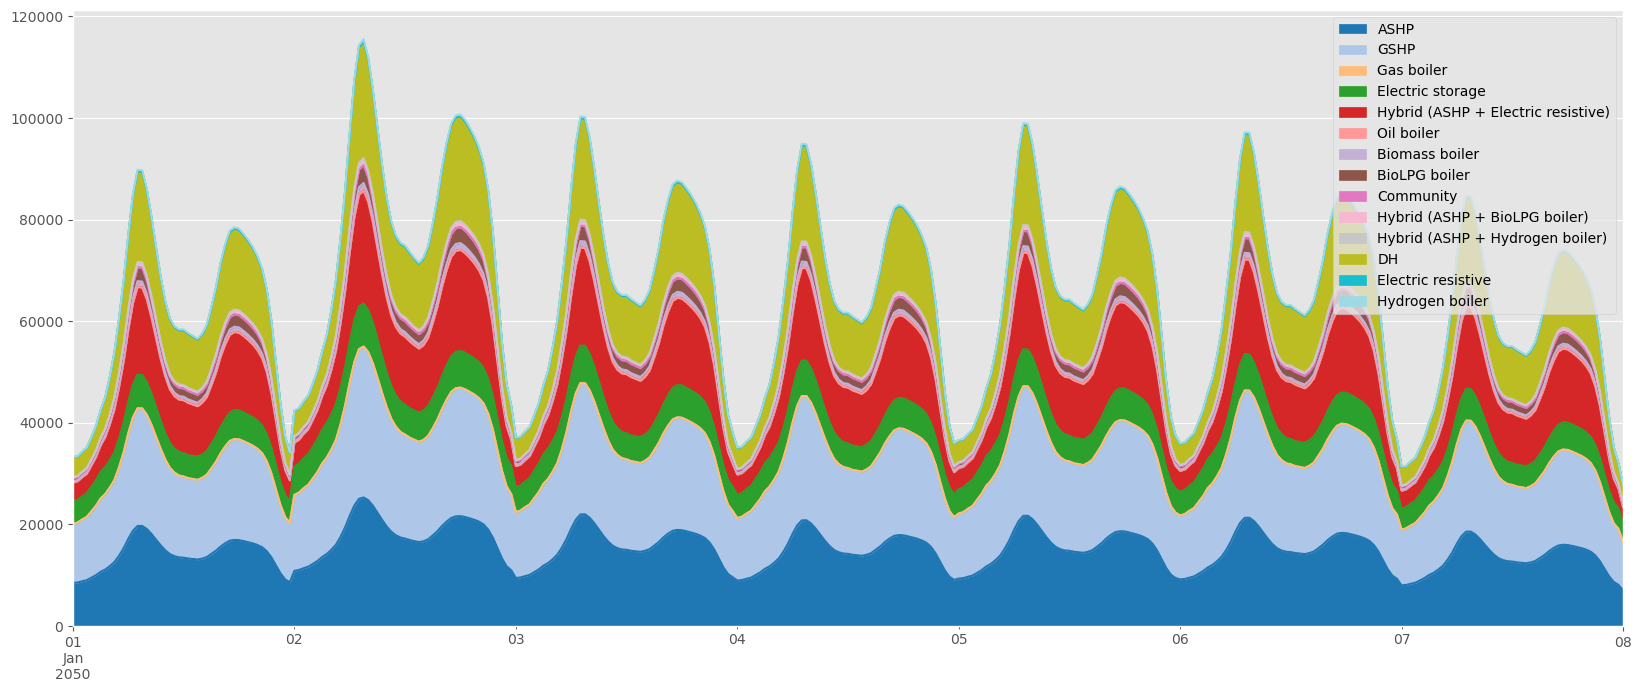

In [14]:
hd_df['2050-01-01 00:00:00': '2050-01-08 00:00:00'].plot.area(figsize=(20,8), cmap='tab20')

In [15]:
scaled_profiles_dict['-3.5_56.0']



,ASHP,GSHP,Gas boiler,Electric storage,Hybrid (ASHP + Electric resistive),Oil boiler,Biomass boiler,BioLPG boiler,Community,Hybrid (ASHP + BioLPG boiler),Hybrid (ASHP + Hydrogen boiler),DH,Electric resistive,Hydrogen boiler
2050-01-01 00:00:00,8456.371112,11636.899950,0.0,4349.275586,3761.946842,0.0,255.057966,585.474693,2.257957,182.452044,55.233224,3897.799528,0.0,67.595597
2050-01-01 00:30:00,8540.880013,11802.914394,0.0,4436.907605,3691.170071,0.0,250.259339,574.459649,2.215476,179.019415,54.194073,3824.466842,0.0,66.323863
2050-01-01 01:00:00,8785.717773,12150.631464,0.0,4571.512406,3767.766515,0.0,255.452536,586.380413,2.261450,182.734294,55.318669,3903.829362,0.0,67.700167
2050-01-01 01:30:00,8999.043055,12441.950571,0.0,4677.327437,3849.013984,0.0,260.961071,599.025019,2.310215,186.674745,56.511551,3988.010868,0.0,69.160041
2050-01-01 02:00:00,9494.119965,13064.363796,0.0,4877.593117,4177.503803,0.0,283.232503,650.148143,2.507378,202.606294,61.334466,4328.363221,0.0,75.062428
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2050-12-31 21:30:00,15683.501935,19180.393864,0.0,5956.922102,12446.295077,0.0,843.852090,1937.026516,7.470385,603.637443,182.737563,12895.759857,0.0,223.638128
2050-12-31 22:00:00,13819.615035,17333.201830,0.0,5632.281421,10018.204802,0.0,679.228879,1559.140951,6.013022,485.876600,147.088135,10379.985572,0.0,180.009598
2050-12-31 22:30:00,11996.449683,15538.128943,0.0,5321.411599,7580.982341,0.0,513.986512,1179.834137,4.550178,367.672851,111.304628,7854.749316,0.0,136.216978
2050-12-31 23:00:00,10633.052232,14199.115064,0.0,5090.236962,5734.559074,0.0,388.800011,892.473858,3.441937,278.122490,84.195284,5941.647394,0.0,103.039985


C:\Users\s2583817\AppData\Local\Temp\ipykernel_18840\600186327.py:10: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  elec_hd_df['ASHP Elec'] = elec_hd_df['ASHP'] / df_ASHP_grid_id[grid_id]
C:\Users\s2583817\AppData\Local\Temp\ipykernel_18840\600186327.py:11: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  elec_hd_df['GSHP Elec'] = elec_hd_df['GSHP'] / df_GSHP_grid_id[grid_id]
C:\Users\s2583817\AppData\Local\Temp\ipykernel_18840\600186327.py:13: SettingWithCopyWarning: 
A value is trying to be set on a copy of 

<Axes: >

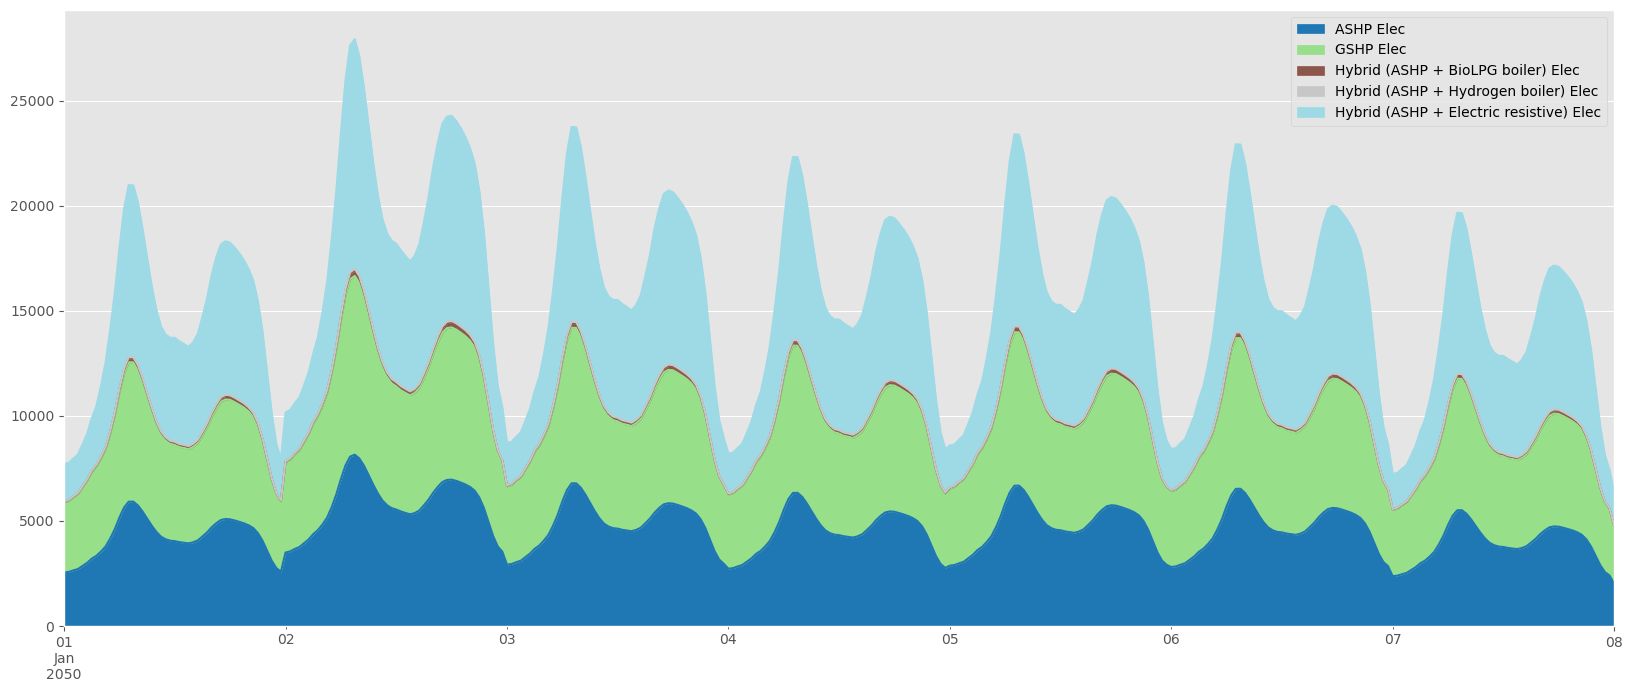

In [16]:
# Select relevant columns
elec_hd_df = hd_df[[
    'ASHP', 'GSHP',
    'Hybrid (ASHP + BioLPG boiler)',
    'Hybrid (ASHP + Hydrogen boiler)',
    'Hybrid (ASHP + Electric resistive)'
]]

# Align all operations by index instead of using .values
elec_hd_df['ASHP Elec'] = elec_hd_df['ASHP'] / df_ASHP_grid_id[grid_id]
elec_hd_df['GSHP Elec'] = elec_hd_df['GSHP'] / df_GSHP_grid_id[grid_id]

elec_hd_df['Hybrid (ASHP + BioLPG boiler) Elec'] = (
    0.75 * elec_hd_df['Hybrid (ASHP + BioLPG boiler)'] / df_ASHP_grid_id[grid_id]
)

elec_hd_df['Hybrid (ASHP + Hydrogen boiler) Elec'] = (
    0.75 * elec_hd_df['Hybrid (ASHP + Hydrogen boiler)'] / df_ASHP_grid_id[grid_id]
)

elec_hd_df['Hybrid (ASHP + Electric resistive) Elec'] = (
    0.75 * elec_hd_df['Hybrid (ASHP + Electric resistive)'] / df_ASHP_grid_id[grid_id]
    + 0.25 * elec_hd_df['Hybrid (ASHP + Electric resistive)']
)

# Plot
elec_hd_df.loc['2050-01-01 00:00:00':'2050-01-08 00:00:00', [
    'ASHP Elec', 'GSHP Elec',
    'Hybrid (ASHP + BioLPG boiler) Elec',
    'Hybrid (ASHP + Hydrogen boiler) Elec',
    'Hybrid (ASHP + Electric resistive) Elec'
]].plot.area(figsize=(20, 8), cmap='tab20')


In [17]:
# elec_hd_df = hd_df[['ASHP', 'GSHP', 'Hybrid (ASHP + BioLPG boiler)', 'Hybrid (ASHP + Hydrogen boiler)', 'Hybrid (ASHP + Electric resistive)']]
# elec_hd_df['ASHP Elec'] = elec_hd_df['ASHP'] / df_ASHP_grid_id[grid_id].values
# elec_hd_df['GSHP Elec'] = elec_hd_df['GSHP'] / df_GSHP_grid_id[grid_id].values
# # assume 75% of electrical demand is met by ASHP for hybrids
# elec_hd_df['Hybrid (ASHP + BioLPG boiler) Elec'] = 0.75 * elec_hd_df['Hybrid (ASHP + BioLPG boiler)'] / df_ASHP_grid_id[grid_id].values
# elec_hd_df['Hybrid (ASHP + Hydrogen boiler) Elec'] = 0.75 * elec_hd_df['Hybrid (ASHP + Hydrogen boiler)'] / df_ASHP_grid_id[grid_id].values
# elec_hd_df['Hybrid (ASHP + Electric resistive) Elec'] = 0.75 * elec_hd_df['Hybrid (ASHP + Electric resistive)'] / df_ASHP_grid_id[grid_id].values + 0.25 * elec_hd_df['Hybrid (ASHP + Electric resistive)']
# elec_hd_df[['ASHP Elec', 'GSHP Elec', 'Hybrid (ASHP + BioLPG boiler) Elec', 'Hybrid (ASHP + Hydrogen boiler) Elec', 'Hybrid (ASHP + Electric resistive) Elec']]['2047-01-01 00:00:00': '2047-01-08 00:00:00'].plot.area(figsize=(20,8), cmap='tab20')

<Axes: >

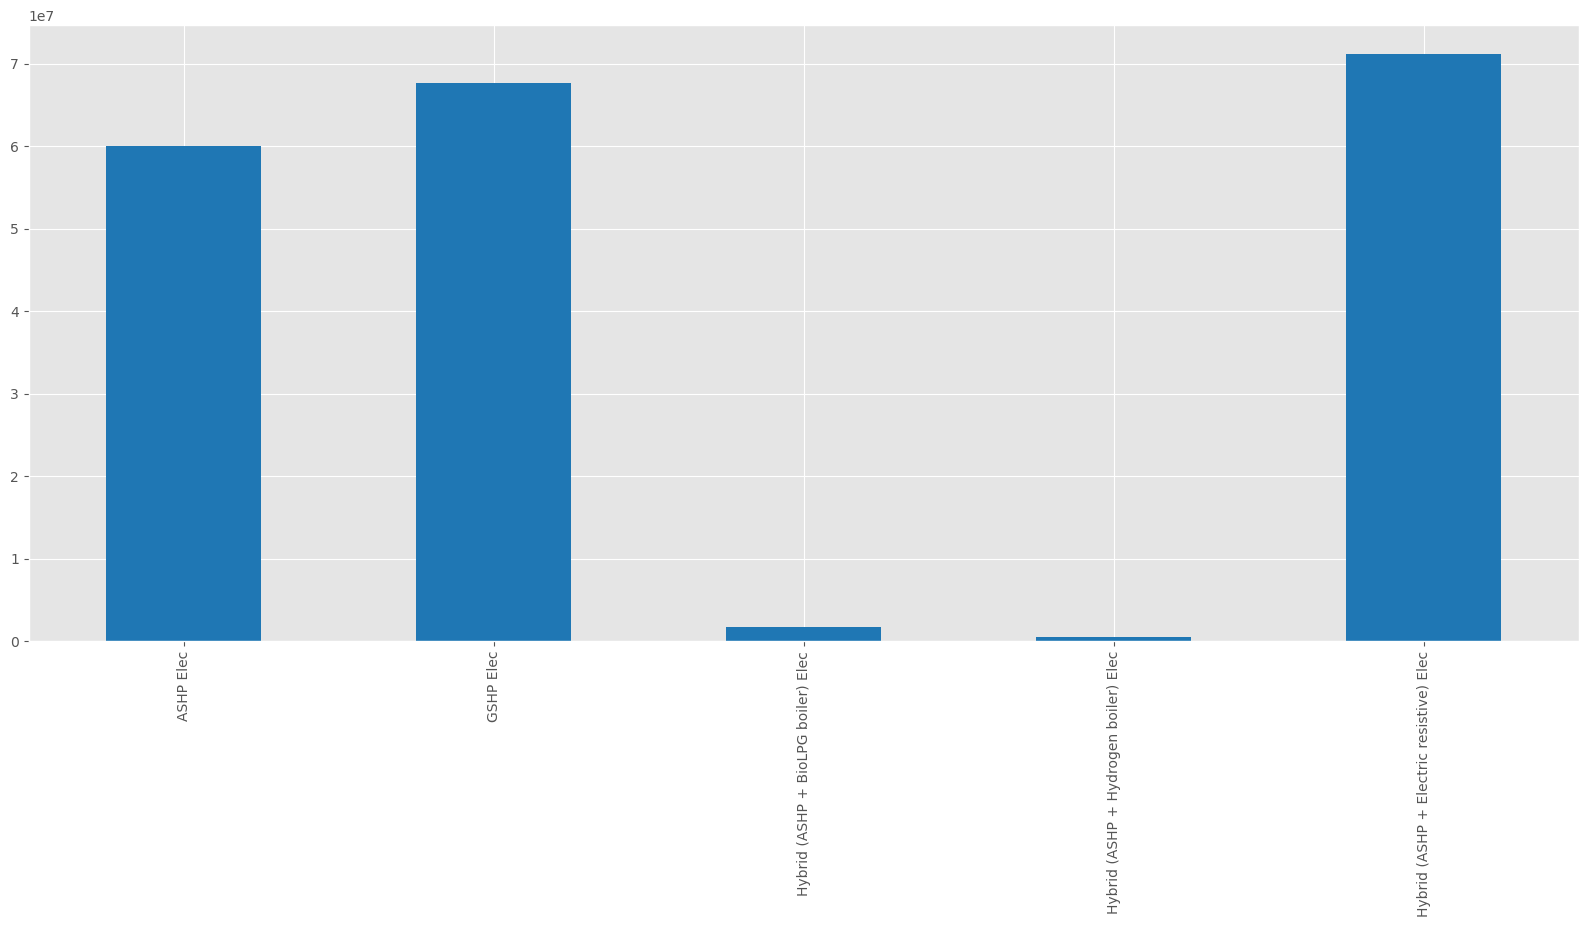

In [18]:
ed_df = elec_hd_df[['ASHP Elec', 'GSHP Elec', 'Hybrid (ASHP + BioLPG boiler) Elec', 'Hybrid (ASHP + Hydrogen boiler) Elec', 'Hybrid (ASHP + Electric resistive) Elec']]
ed_df.sum().plot.bar(figsize=(20,8), cmap='tab20')

In [19]:
# total in GWh
ed_df.sum().sum() / 1000000

200.93836366078702